In [1]:
import pypyodbc
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from collections import Counter
import re


# Configurações de exibição e silenciamento de avisos
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('future.no_silent_downcasting', True)

def conectar():
    return pypyodbc.connect("Driver={HFSQL};Server Name=localhost;Server Port=4900;Database=A37278473;UID=admin;PWD=;")

def auditoria_e_exibicao_datasets():
    tabelas_alvo = ['TAB_VENDA_ITEM', 'TAB_VENDA', 'TAB_PRODUTO', 'TAB_ENTIDADE']
    datasets_finais = {}

    print("="*80)
    print(f"📋 1. ESCOPO DA ANÁLISE: {', '.join(tabelas_alvo)}")
    print("="*80)

    for tabela in tabelas_alvo:
        print(f"\n\n▶️ PROCESSANDO TABELA: {tabela}")
        conn = conectar()
        cursor = conn.cursor()
        
        try:
            # --- ETAPA: CONTAGEM DE CAMPOS ---
            cursor.execute(f"SELECT TOP 1 * FROM {tabela}")
            colunas_originais = [column[0] for column in cursor.description]
            print(f"   📊 Estrutura Original: {len(colunas_originais)} campos identificados.")

            # --- ETAPA: EXTRAÇÃO E LIMPEZA (CASTING) ---
            colunas_sql = ", ".join([f"CAST({c} AS VARCHAR(255)) AS {c}" for c in colunas_originais])
            cursor.execute(f"SELECT {colunas_sql} FROM {tabela}")
            df = pd.DataFrame([list(r) for r in cursor.fetchall()], columns=colunas_originais)
            conn.close()

            # Normalização de nulos
            df = df.replace(r'^\s*$', np.nan, regex=True).replace('None', np.nan)
            total_rows = len(df)

            campos_integros = []
            campos_para_remover = []

            for col in colunas_originais:
                nulos = df[col].isnull().sum()
                distintos = df[col].nunique()

                # --- ETAPA: IDENTIFICAÇÃO DE CAMPOS PREENCHIDOS ---
                if nulos == 0:
                    campos_integros.append(col)

                # --- ETAPA: IDENTIFICAÇÃO DE MOTIVOS DE REMOÇÃO ---
                if nulos == total_rows:
                    campos_para_remover.append((col, "100% Nulo (Sem dados registrados)"))
                elif distintos <= 1:
                    val = df[col].dropna().unique()[0] if distintos == 1 else "Vazio"
                    campos_para_remover.append((col, f"Valor Constante ('{val}') - Sem variância para IA"))

            print(f"   ✅ Campos com 100% de preenchimento: {len(campos_integros)}")
            
            # --- ETAPA: EXIBIÇÃO DE REMOÇÕES E MOTIVOS ---
            if campos_para_remover:
                print(f"   ❌ CAMPOS REMOVIDOS E MOTIVOS:")
                for col_rem, motivo in campos_para_remover:
                    print(f"      - {col_rem}: {motivo}")
            else:
                print(f"   ✨ Nenhum campo removido (Tabela com alta variância).")

            # --- ETAPA: EXIBIÇÃO DO DATASET FINAL (SANEADO) ---
            cols_remover = [c[0] for c in campos_para_remover]
            df_final = df.drop(columns=cols_remover)
            datasets_finais[tabela] = df_final
            
            print(f"\n   📄 DATASET FINAL SANEADO ({tabela}):")
            print(df_final.head(5)) # Mostra as 5 primeiras linhas do dataset limpo
            print(f"\n   💡 Resultado: {len(df_final.columns)} colunas mantidas.")
            print("-" * 40)

        except Exception as e:
            print(f"   💥 Erro ao processar {tabela}: {e}")
            if conn: conn.close()

    return datasets_finais

if __name__ == "__main__":
    datasets = auditoria_e_exibicao_datasets()

📋 1. ESCOPO DA ANÁLISE: TAB_VENDA_ITEM, TAB_VENDA, TAB_PRODUTO, TAB_ENTIDADE


▶️ PROCESSANDO TABELA: TAB_VENDA_ITEM
   📊 Estrutura Original: 45 campos identificados.
   ✅ Campos com 100% de preenchimento: 38
   ❌ CAMPOS REMOVIDOS E MOTIVOS:
      - obs: 100% Nulo (Sem dados registrados)
      - grade_id: Valor Constante ('0') - Sem variância para IA
      - cor_id: Valor Constante ('0') - Sem variância para IA
      - tabela: Valor Constante ('1') - Sem variância para IA
      - altura: Valor Constante ('0') - Sem variância para IA
      - largura: Valor Constante ('0') - Sem variância para IA
      - altlar: Valor Constante ('0') - Sem variância para IA
      - locacao_dt_ini: 100% Nulo (Sem dados registrados)
      - locacao_dt_fin: 100% Nulo (Sem dados registrados)
      - locacao_status: Valor Constante ('0') - Sem variância para IA
      - sinal: Valor Constante ('0') - Sem variância para IA
      - locacao_dt_prova: 100% Nulo (Sem dados registrados)
      - vendedor_id: Valor Co

📊 INICIANDO EDA (ANÁLISE EXPLORATÓRIA DE DADOS) - FATEC 2026

📈 INSIGHTS DE FATURAMENTO:
   - Ticket Médio: R$ 46.50
   - Valor Máximo em uma Venda: R$ 2257.70


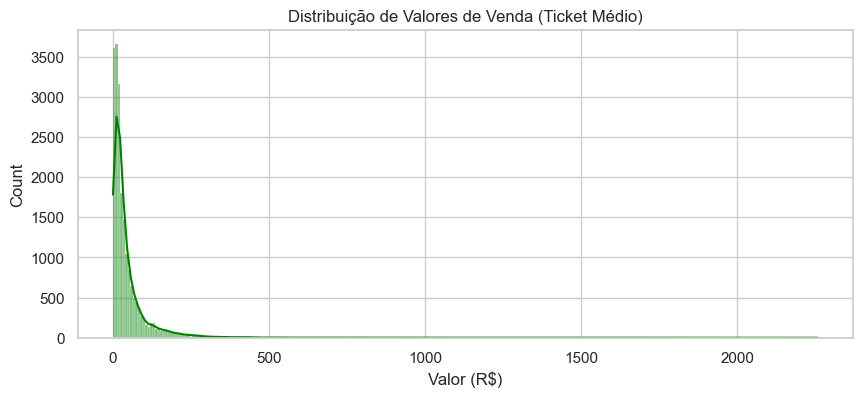


📦 INSIGHTS DE PRODUTOS (TOP 10):


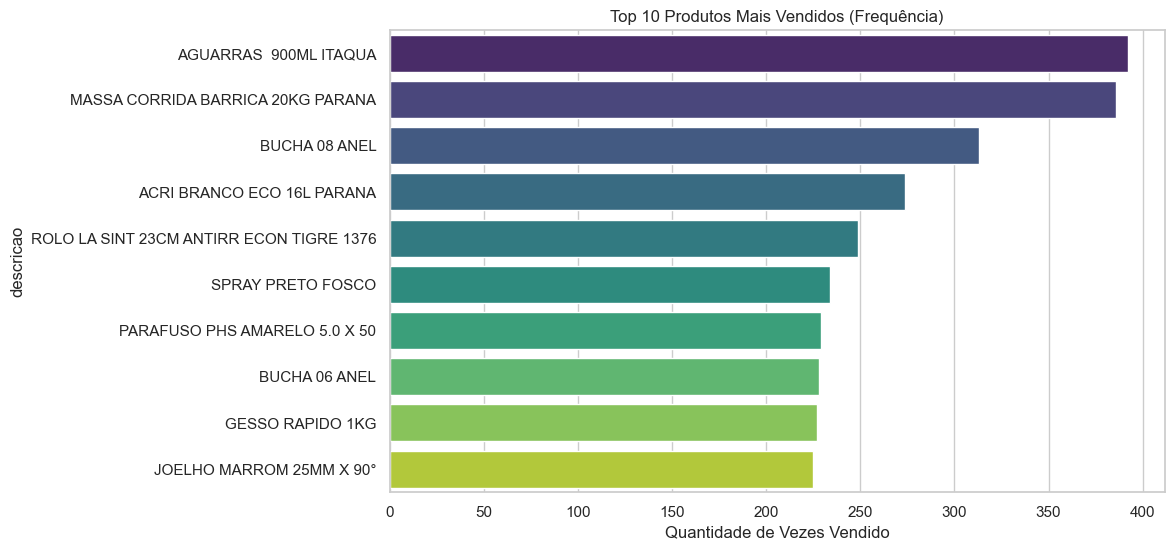


🔗 INSIGHTS DE CESTA DE COMPRAS:
   - Média de itens por cupom: 2.06 itens


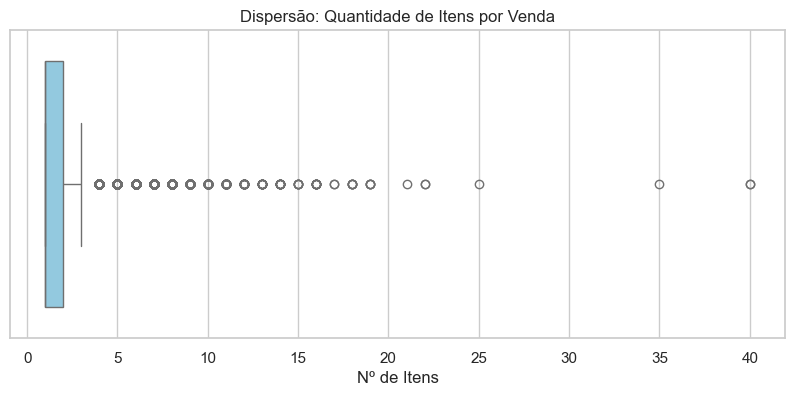

In [2]:


# Configurações visuais para o relatório
plt.style.use('seaborn-v0_8-muted')
sns.set_theme(style="whitegrid")

def executar_eda_completa(datasets):
    print("="*80)
    print("📊 INICIANDO EDA (ANÁLISE EXPLORATÓRIA DE DADOS) - FATEC 2026")
    print("="*80)

    # 1. ANÁLISE DE VENDAS (TAB_VENDA) - Ticket Médio e Volume
    if 'TAB_VENDA' in datasets:
        df_v = datasets['TAB_VENDA']
        # Conversão de valores para numérico (coagindo erros em NaN)
        col_valor = 'ven_cur_subtotal' # Ajuste para o nome real da sua coluna de total
        df_v[col_valor] = pd.to_numeric(df_v[col_valor], errors='coerce')
        
        print(f"\n📈 INSIGHTS DE FATURAMENTO:")
        print(f"   - Ticket Médio: R$ {df_v[col_valor].mean():.2f}")
        print(f"   - Valor Máximo em uma Venda: R$ {df_v[col_valor].max():.2f}")
        
        plt.figure(figsize=(10, 4))
        sns.histplot(df_v[col_valor].dropna(), kde=True, color='green')
        plt.title('Distribuição de Valores de Venda (Ticket Médio)')
        plt.xlabel('Valor (R$)')
        plt.show()

    # 2. ANÁLISE DE PRODUTOS (TAB_VENDA_ITEM) - Curva ABC (Pareto)
    if 'TAB_VENDA_ITEM' in datasets:
        df_i = datasets['TAB_VENDA_ITEM']
        print(f"\n📦 INSIGHTS DE PRODUTOS (TOP 10):")
        
        # Frequência de vendas por produto
        top_produtos = df_i['descricao'].value_counts().head(10)
        
        plt.figure(figsize=(10, 6))
        sns.barplot(x=top_produtos.values, y=top_produtos.index, palette='viridis')
        plt.title('Top 10 Produtos Mais Vendidos (Frequência)')
        plt.xlabel('Quantidade de Vezes Vendido')
        plt.show()

    # 3. ANÁLISE DE DENSIDADE (ITENS POR VENDA)
    if 'TAB_VENDA_ITEM' in datasets:
        itens_venda = df_i.groupby('ven_id').size()
        print(f"\n🔗 INSIGHTS DE CESTA DE COMPRAS:")
        print(f"   - Média de itens por cupom: {itens_venda.mean():.2f} itens")
        
        plt.figure(figsize=(10, 4))
        sns.boxplot(x=itens_venda, color='skyblue')
        plt.title('Dispersão: Quantidade de Itens por Venda')
        plt.xlabel('Nº de Itens')
        plt.show()

    # 4. QUALIDADE FINAL (MAPA DE CALOR DE CORRELAÇÃO)
    # Seleciona apenas colunas numéricas para correlação
    df_num = df_i.select_dtypes(include=['float64', 'int64'])
    if not df_num.empty:
        plt.figure(figsize=(8, 6))
        sns.heatmap(df_num.corr(), annot=True, cmap='coolwarm', fmt=".2f")
        plt.title('Matriz de Correlação entre Atributos')
        plt.show()

# Chamada da função passando os datasets limpos da etapa anterior
executar_eda_completa(datasets)

📋 ESTRUTURA E TIPAGEM DE DADOS - TAB_VENDA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20132 entries, 0 to 20131
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ven_id                   20132 non-null  object 
 1   ven_id_forma_pagamento   20132 non-null  object 
 2   ven_id_operacao          20132 non-null  object 
 3   ven_dt_data              20132 non-null  object 
 4   ven_cur_subtotal         20132 non-null  float64
 5   ven_cur_acrescimo_ounao  20132 non-null  object 
 6   ven_id_entidade          20132 non-null  object 
 7   ven_boo_cancelado        20132 non-null  object 
 8   ven_hor_hora             20132 non-null  object 
 9   ven_cur_total            20132 non-null  object 
 10  ven_cod                  20132 non-null  object 
 11  id_os                    20132 non-null  object 
 12  cnpjcpf                  20132 non-null  object 
 13  ven_id_vendedor          20132 no

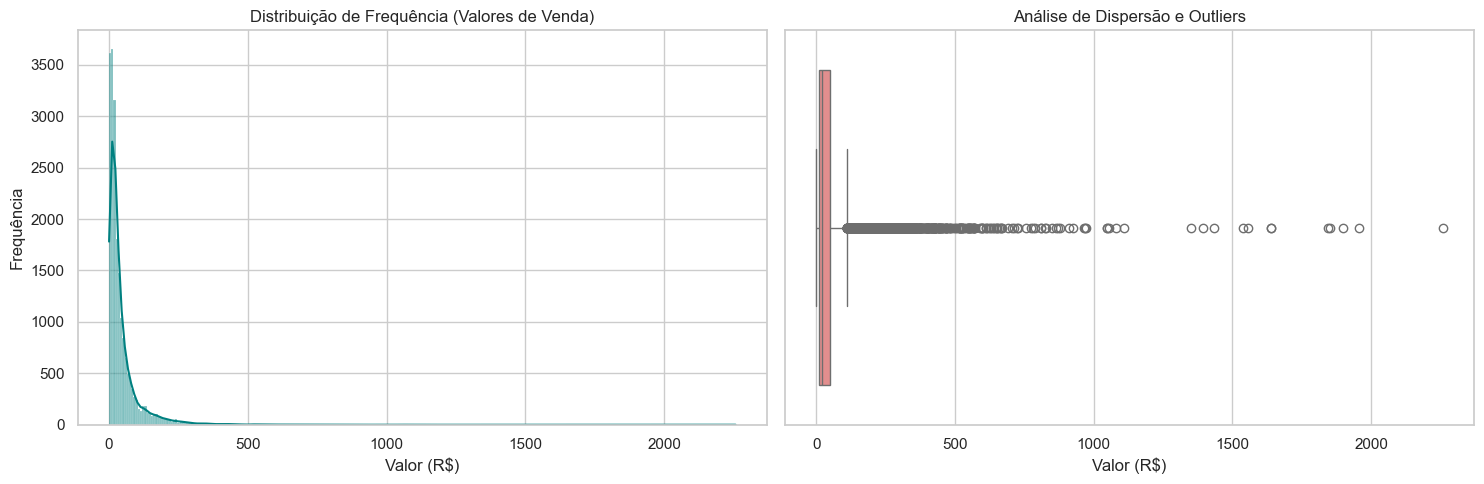

In [3]:
def eda_detalhado_vendas(datasets):
    if 'TAB_VENDA' not in datasets:
        print("❌ Erro: Dataset TAB_VENDA não encontrado.")
        return

    df = datasets['TAB_VENDA'].copy()

    # 1. ANÁLISE DE ESTRUTURA E TIPAGEM
    print("="*60)
    print("📋 ESTRUTURA E TIPAGEM DE DADOS - TAB_VENDA")
    print("="*60)
    print(df.info())

    # 2. SANEAMENTO PARA CÁLCULOS (Conversão de Texto para Numérico)
    # Identificamos a coluna de subtotal para cálculos estatísticos
    col_valor = 'ven_cur_subtotal' 
    df[col_valor] = pd.to_numeric(df[col_valor], errors='coerce')

    # 3. ESTATÍSTICA DESCRITIVA (Médias, Totais, Contagens, Quartis)
    print("\n" + "="*60)
    print("🔢 MÉTRICAS ESTATÍSTICAS (RESUMO EXECUTIVO)")
    print("="*60)
    estatisticas = df[col_valor].describe()
    print(f"   - Total de Vendas (Contagem): {int(estatisticas['count'])}")
    print(f"   - Faturamento Total (Soma): R$ {df[col_valor].sum():.2f}")
    print(f"   - Ticket Médio (Média): R$ {estatisticas['mean']:.2f}")
    print(f"   - Mediana: R$ {df[col_valor].median():.2f}")
    print(f"   - Desvio Padrão: R$ {estatisticas['std']:.2f}")
    print(f"   - Valor Mínimo: R$ {estatisticas['min']:.2f}")
    print(f"   - Valor Máximo: R$ {estatisticas['max']:.2f}")

    # 4. ANÁLISE DE DISTRIBUIÇÃO E OUTLIERS (VISUAL)
    print("\n📈 Gerando Gráficos de Distribuição...")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    # Histograma (Densidade e Frequência)
    sns.histplot(df[col_valor].dropna(), kde=True, color='teal', ax=ax1)
    ax1.set_title('Distribuição de Frequência (Valores de Venda)')
    ax1.set_xlabel('Valor (R$)')
    ax1.set_ylabel('Frequência')

    # Boxplot (Identificação de Outliers/Anomalias)
    sns.boxplot(x=df[col_valor].dropna(), color='lightcoral', ax=ax2)
    ax2.set_title('Análise de Dispersão e Outliers')
    ax2.set_xlabel('Valor (R$)')

    plt.tight_layout()
    plt.show()

# Execução do EDA específico
eda_detalhado_vendas(datasets)

In [4]:
import pandas as pd

def filtrar_vendas_invalidas(datasets):
    if 'TAB_VENDA' not in datasets:
        print("❌ Erro: Tabela TAB_VENDA não encontrada nos datasets.")
        return datasets

    df_vendas = datasets['TAB_VENDA'].copy()
    col_valor = 'ven_cur_subtotal' # Nome da coluna de valor total
    
    # 1. Garantir tipagem numérica para a operação
    df_vendas[col_valor] = pd.to_numeric(df_vendas[col_valor], errors='coerce')
    
    # 2. Métricas antes da exclusão
    total_original = len(df_vendas)
    
    # 3. Aplicar Filtro: Manter apenas vendas com valor real (> 0)
    df_limpo = df_vendas[df_vendas[col_valor] > 0].dropna(subset=[col_valor])
    
    # 4. Cálculos de Impacto
    total_atual = len(df_limpo)
    qtd_excluida = total_original - total_atual
    representatividade = (qtd_excluida / total_original) * 100
    
    # Atualizar o dicionário global de datasets
    datasets['TAB_VENDA'] = df_limpo

    # --- IMPRESSÃO DOS RESULTADOS ---
    print("="*60)
    print("🛡️ RELATÓRIO DE SANEAMENTO: EXCLUSÃO DE VENDAS ZERADAS")
    print("="*60)
    print(f"   - Total original de registros: {total_original}")
    print(f"   - Vendas excluídas (Valor <= 0): {qtd_excluida}")
    print(f"   - Impacto no dataset: {representatividade:.2f}% dos dados removidos")
    print(f"   - Dataset final para IA: {total_atual} registros válidos")
    print("="*60)

    return datasets

# Execução
datasets = filtrar_vendas_invalidas(datasets)

🛡️ RELATÓRIO DE SANEAMENTO: EXCLUSÃO DE VENDAS ZERADAS
   - Total original de registros: 20132
   - Vendas excluídas (Valor <= 0): 224
   - Impacto no dataset: 1.11% dos dados removidos
   - Dataset final para IA: 19908 registros válidos


🧠 EDA PARA SISTEMA DE RECOMENDAÇÃO: ANÁLISE DE AFINIDADE
🧹 SANEAMENTO DE ITENS (REFERENTE A VENDAS ZERADAS):
   - Registros na TAB_VENDA_ITEM antes: 41381
   - Registros após remover vendas zeradas: 40887
   - Total de itens excluídos: 494 (1.19%)
--------------------------------------------------------------------------------
📊 ESPARSIDADE DA MATRIZ: 99.9466%
🛒 MÉDIA DE ITENS POR VENDA: 1.99


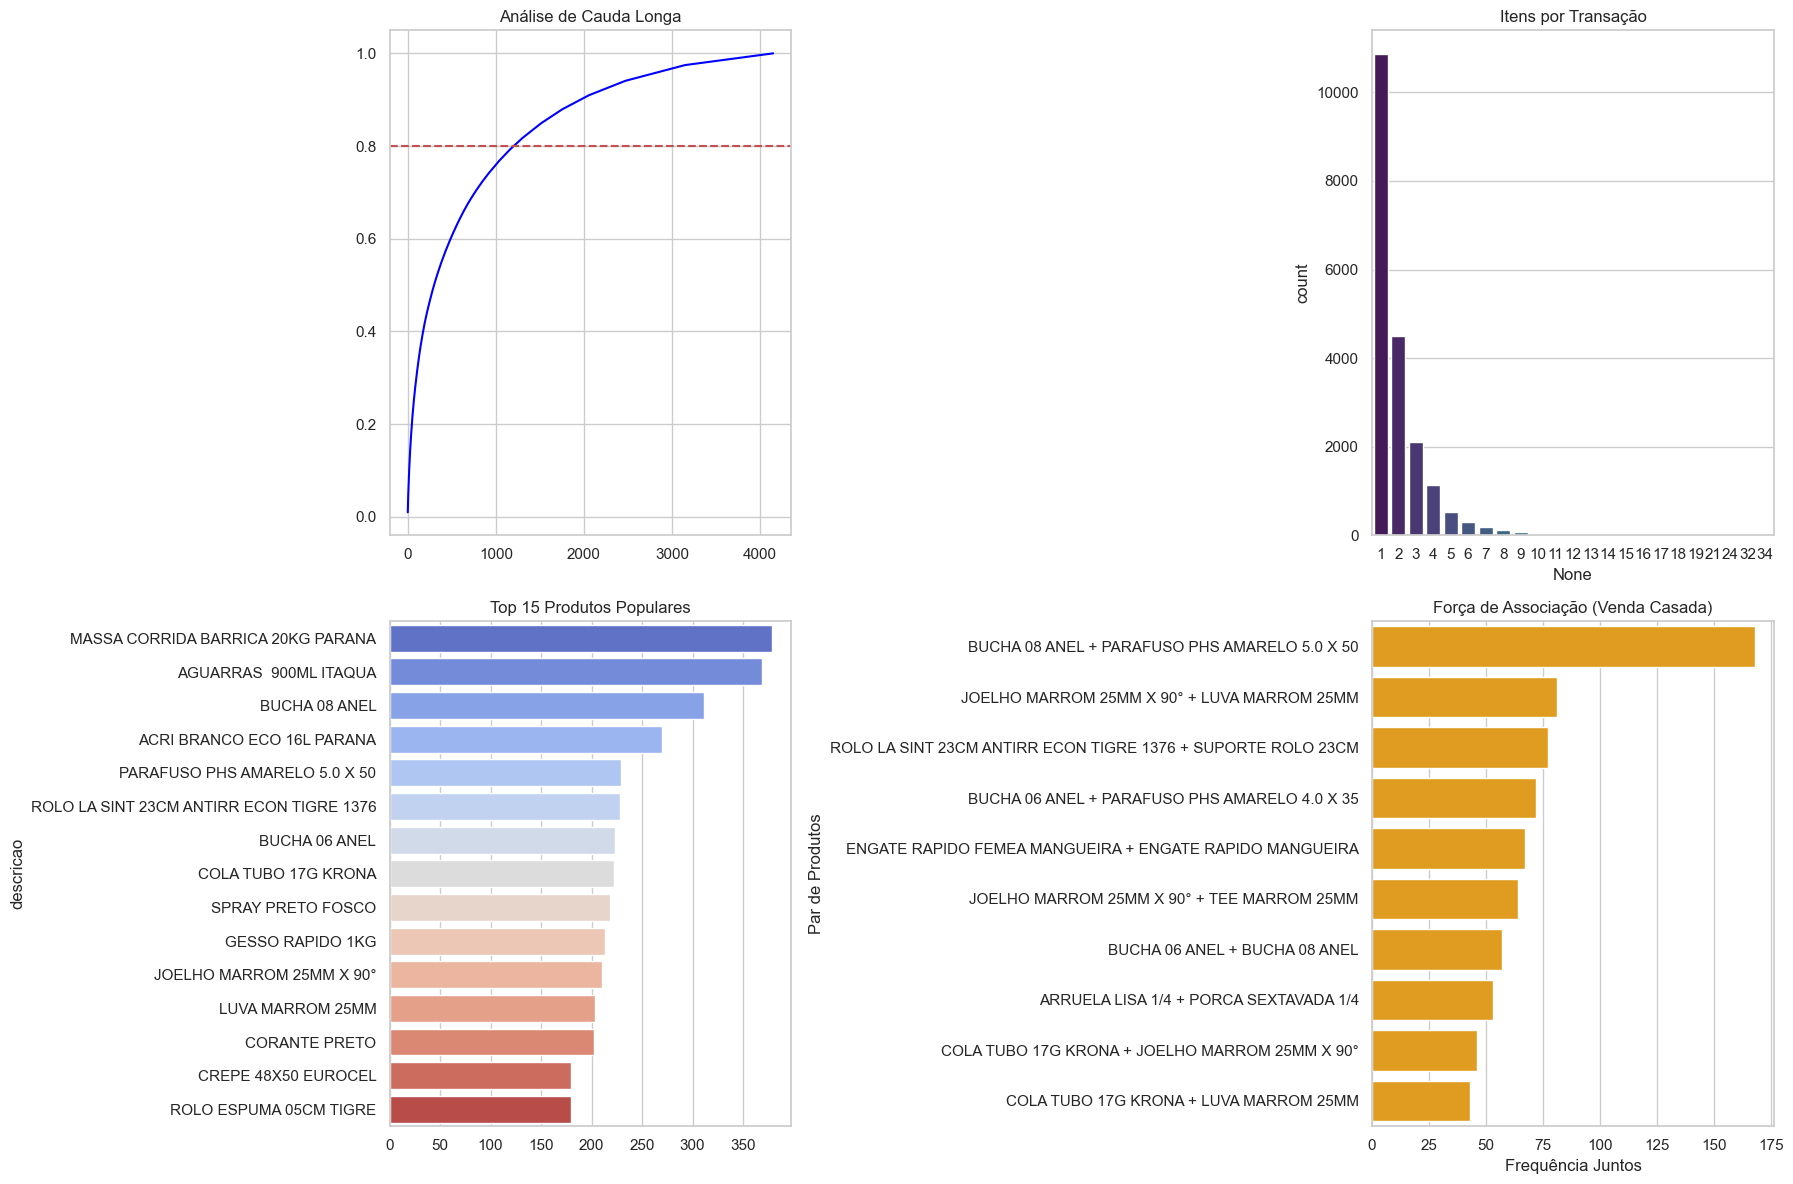

In [5]:


warnings.filterwarnings('ignore')

def eda_recomendacao_venda_item(datasets):
    if 'TAB_VENDA_ITEM' not in datasets or 'TAB_VENDA' not in datasets:
        print("❌ Tabelas necessárias ausentes.")
        return

    df_vendas = datasets['TAB_VENDA']
    df_itens_raw = datasets['TAB_VENDA_ITEM']
    
    # --- NOVO: CÁLCULO DE LIMPEZA ---
    total_antes = len(df_itens_raw)
    
    # Inner Join implícito: mantém apenas itens cujas vendas existem no dataset limpo (sem zeradas)
    df = df_itens_raw[df_itens_raw['ven_id'].isin(df_vendas['ven_id'])].copy()
    
    total_depois = len(df)
    qtd_excluida = total_antes - total_depois
    perc_reducao = (qtd_excluida / total_antes) * 100 if total_antes > 0 else 0
    
    # Removendo duplicatas para análise de afinidade (presença na cesta)
    df_presenca = df.drop_duplicates(subset=['ven_id', 'pro_id'])

    print("="*80)
    print("🧠 EDA PARA SISTEMA DE RECOMENDAÇÃO: ANÁLISE DE AFINIDADE")
    print("="*80)
    
    # Exibição da limpeza de registros
    print(f"🧹 SANEAMENTO DE ITENS (REFERENTE A VENDAS ZERADAS):")
    print(f"   - Registros na TAB_VENDA_ITEM antes: {total_antes}")
    print(f"   - Registros após remover vendas zeradas: {total_depois}")
    print(f"   - Total de itens excluídos: {qtd_excluida} ({perc_reducao:.2f}%)")
    print("-" * 80)

    # --- METRICA 1: ESPARSIDADE ---
    n_usuarios = df['ven_id'].nunique() 
    n_itens = df['pro_id'].nunique()
    # Evita divisão por zero se o dataset estiver vazio
    if n_usuarios > 0 and n_itens > 0:
        esparsidade = (1 - (len(df_presenca) / (n_usuarios * n_itens))) * 100
    else:
        esparsidade = 0
    print(f"📊 ESPARSIDADE DA MATRIZ: {esparsidade:.4f}%")

    # --- METRICA 2: DENSIDADE DE CESTA ---
    cesta_size = df_presenca.groupby('ven_id').size()
    print(f"🛒 MÉDIA DE ITENS POR VENDA: {cesta_size.mean():.2f}")

    # --- METRICA 3: COOCORRÊNCIA ---
    vendas_agrupadas = df_presenca.groupby('ven_id')['descricao'].apply(list) # Usando seu campo real
    pares = Counter()
    for itens in vendas_agrupadas:
        if len(itens) > 1:
            pares.update(combinations(sorted(itens), 2))

    dados_grafico = []
    for (p1, p2), freq in pares.most_common(10):
        dados_grafico.append({
            'Par de Produtos': f"{p1} + {p2}",
            'Frequência Juntos': freq
        })
    
    top_pares = pd.DataFrame(dados_grafico)

    # --- VISUALIZAÇÕES ---
    fig, ax = plt.subplots(2, 2, figsize=(18, 12))

    # Gráfico 1: Long Tail
    item_counts = df_presenca['descricao'].value_counts(normalize=True).cumsum()
    ax[0,0].plot(range(len(item_counts)), item_counts.values, color='blue')
    ax[0,0].axhline(y=0.8, color='r', linestyle='--')
    ax[0,0].set_title('Análise de Cauda Longa')

    # Gráfico 2: Distribuição de Itens
    sns.countplot(x=cesta_size, ax=ax[0,1], palette='viridis')
    ax[0,1].set_title('Itens por Transação')

    # Gráfico 3: Top Itens Individuais
    top_15 = df_presenca['descricao'].value_counts().head(15)
    sns.barplot(x=top_15.values, y=top_15.index, ax=ax[1,0], palette='coolwarm')
    ax[1,0].set_title('Top 15 Produtos Populares')

    # Gráfico 4: Força de Associação
    if not top_pares.empty:
        sns.barplot(data=top_pares, x='Frequência Juntos', y='Par de Produtos', ax=ax[1,1], color='orange')
        ax[1,1].set_title('Força de Associação (Venda Casada)')

    plt.tight_layout()
    plt.show()
    
    # Atualiza o dataset para as próximas etapas
    datasets['TAB_VENDA_ITEM'] = df
    return datasets

# Executar
datasets = eda_recomendacao_venda_item(datasets)

📝 ANÁLISE SEMÂNTICA DE 'pro_txt_descricao'
   - Total de produtos únicos analisados: 5051
   - Padrões de 3 palavras repetidos encontrados: 1665


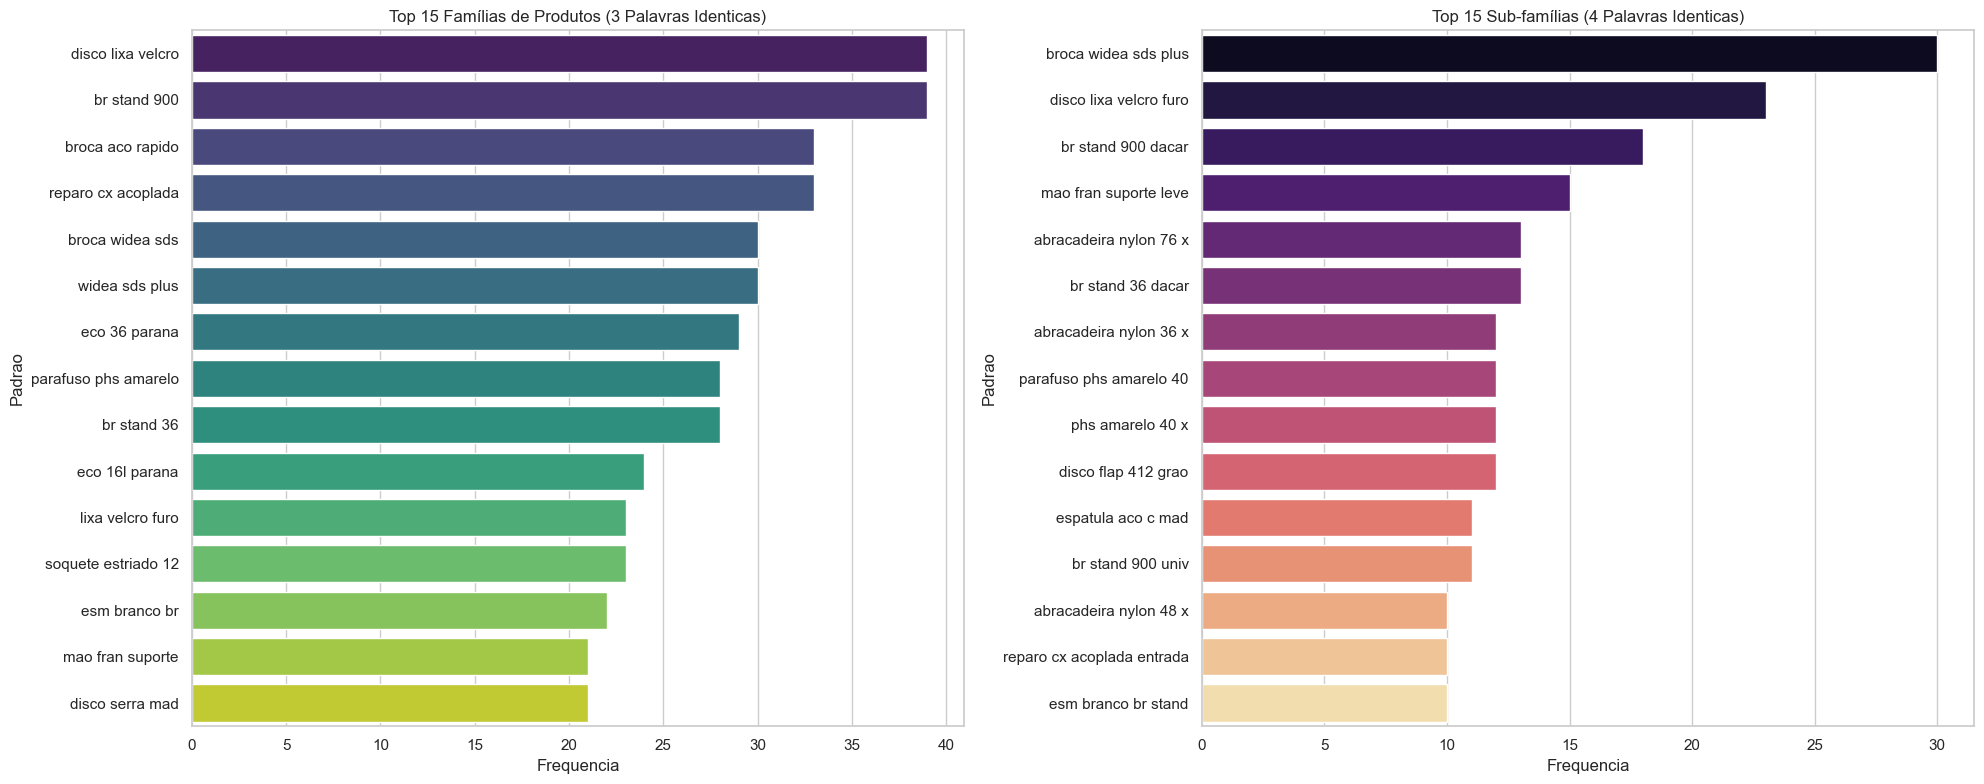


🔍 DETECÇÃO DE DUPLICIDADE / VARIAÇÃO:
   📦 Cluster [ABRACADEIRA NYLON 25]: 4 variações detectadas.
      Exemplos: ['ABRACADEIRA NYLON 2,5 X 200 PT UN', 'ABRACADEIRA NYLON 2,5 X 150 BR UN', 'ABRACADEIRA NYLON 2,5 X 150 PT UN']
   📦 Cluster [ABRACADEIRA NYLON 36]: 13 variações detectadas.
      Exemplos: ['ABRACADEIRA NYLON 3,6 X 150 BR UN', 'ABRACADEIRA NYLON 3,6 X 300 UN', 'ABRACADEIRA NYLON 3,6 X 200 BR UN']
   📦 Cluster [ABRACADEIRA NYLON 48]: 10 variações detectadas.
      Exemplos: ['ABRACADEIRA NYLON 4,8 X 200 UN PT', 'ABRACADEIRA NYLON 4,8 X 400 UN', 'ABRACADEIRA NYLON 4,8 X 300 BR']
   📦 Cluster [ABRACADEIRA NYLON 76]: 13 variações detectadas.
      Exemplos: ['ABRACADEIRA NYLON 7,6 X 400 PT', 'ABRACADEIRA NYLON 7,6 X 400 BR', 'ABRACADEIRA NYLON 7,6 X 500 PT UN']
   📦 Cluster [ACABAMENTO VOLANTE METAL]: 5 variações detectadas.
      Exemplos: ['ACABAMENTO VOLANTE METAL C23', 'ACABAMENTO VOLANTE METAL C64', 'ACABAMENTO VOLANTE METAL C33']
   📦 Cluster [ACRI ALGODAO EGIP]: 7 var

In [6]:

def eda_robustez_textual(datasets):
    if 'TAB_PRODUTO' not in datasets:
        print("❌ Tabela TAB_PRODUTO não encontrada.")
        return datasets

    df_p = datasets['TAB_PRODUTO'].copy()
    col_desc = 'pro_txt_descricao'

    # 1. PRÉ-PROCESSAMENTO PARA NLP (Natural Language Processing)
    # Removemos pontuação, números e deixamos tudo em minúsculo
    def limpar_texto(txt):
        txt = str(txt).lower()
        txt = re.sub(r'[^\w\s]', '', txt) # Remove pontuação
        return txt.strip()

    df_p['desc_clean'] = df_p[col_desc].apply(limpar_texto)

    # 2. IDENTIFICAÇÃO DE PADRÕES DE 3 E 4 PALAVRAS (N-GRAMS)
    def extrair_ngramas(txt, n):
        palavras = txt.split()
        if len(palavras) < n: return []
        return [" ".join(palavras[i:i+n]) for i in range(len(palavras)-n+1)]

    ngrams_3 = []
    ngrams_4 = []
    for d in df_p['desc_clean']:
        ngrams_3.extend(extrair_ngramas(d, 3))
        ngrams_4.extend(extrair_ngramas(d, 4))

    count_3 = Counter(ngrams_3).most_common(15)
    count_4 = Counter(ngrams_4).most_common(15)

    df_ng3 = pd.DataFrame(count_3, columns=['Padrao', 'Frequencia'])
    df_ng4 = pd.DataFrame(count_4, columns=['Padrao', 'Frequencia'])

    print("="*80)
    print(f"📝 ANÁLISE SEMÂNTICA DE '{col_desc}'")
    print("="*80)
    print(f"   - Total de produtos únicos analisados: {len(df_p)}")
    print(f"   - Padrões de 3 palavras repetidos encontrados: {len([k for k,v in Counter(ngrams_3).items() if v > 1])}")

    # 3. VISUALIZAÇÃO DE CLUSTERS TEXTUAIS
    fig, ax = plt.subplots(1, 2, figsize=(20, 8))

    # Gráfico A: Padrões de 3 palavras (Famílias de produtos)
    sns.barplot(data=df_ng3, x='Frequencia', y='Padrao', palette='viridis', ax=ax[0])
    ax[0].set_title('Top 15 Famílias de Produtos (3 Palavras Identicas)')

    # Gráfico B: Padrões de 4 palavras (Produtos Quase Identicos)
    sns.barplot(data=df_ng4, x='Frequencia', y='Padrao', palette='magma', ax=ax[1])
    ax[1].set_title('Top 15 Sub-famílias (4 Palavras Identicas)')

    plt.tight_layout()
    plt.show()

    # 4. INSIGHT DE AGRUPAMENTO (Dicionário de Sinônimos)
    print("\n🔍 DETECÇÃO DE DUPLICIDADE / VARIAÇÃO:")
    # Agrupa por 3 primeiras palavras para ver variações de tamanho/cor/sabor
    df_p['prefixo_3'] = df_p['desc_clean'].apply(lambda x: " ".join(x.split()[:3]))
    grupos = df_p.groupby('prefixo_3')[col_desc].apply(list)
    
    # Mostra apenas grupos que tem mais de 3 produtos similares
    for prefixo, lista in grupos.items():
        if len(lista) >= 3:
            print(f"   📦 Cluster [{prefixo.upper()}]: {len(lista)} variações detectadas.")
            print(f"      Exemplos: {lista[:3]}")

    return datasets

# Executar
datasets = eda_robustez_textual(datasets)

In [7]:

def criar_produto_mestre(datasets):
    if 'TAB_PRODUTO' not in datasets:
        print("❌ Erro: TAB_PRODUTO não encontrada.")
        return datasets

    df_prod = datasets['TAB_PRODUTO'].copy()
    
    # 1. Função de Limpeza para extrair a "Essência" do produto
    def extrair_mestre(txt):
        txt = str(txt).upper()
        # Remove números e unidades de medida (ML, KG, G, UN, etc)
        txt = re.sub(r'\d+\s*(ML|KG|G|GR|UN|LT|L|CX|PCT|LT|UNIDADE)', '', txt)
        # Remove caracteres especiais
        txt = re.sub(r'[^\w\s]', '', txt)
        # Retorna as primeiras 3 palavras (Geralmente Marca + Tipo + Sabor/Modelo)
        palavras = txt.split()
        return " ".join(palavras[:3]) if len(palavras) >= 3 else " ".join(palavras)

    # Criando a descrição mestre
    df_prod['pro_txt_mestre'] = df_prod['pro_txt_descricao'].apply(extrair_mestre)

    # 2. Agrupamento para criar o ID Mestre
    # Cada grupo de descrições similares ganha um ID único
    df_mestre = df_prod.groupby('pro_txt_mestre').agg({
        'pro_id': list, # Guarda a lista de IDs originais que pertencem a este mestre
        'pro_txt_descricao': 'first' # Uma descrição de exemplo para conferência
    }).reset_index()

    # Criar um ID Mestre sequencial (ex: começando em 5000)
    df_mestre['pro_id_mestre'] = range(5000, 5000 + len(df_mestre))
    df_mestre = df_mestre.rename(columns={'pro_id': 'lista_ids_originais'})

    print("="*80)
    print("🏗️  DATASET MESTRE CONSTRUÍDO")
    print("="*80)
    print(f"   - SKUs originais processados: {len(df_prod)}")
    print(f"   - Entidades Mestres geradas: {len(df_mestre)}")
    print(f"   - Ganho de densidade (Redução): {((len(df_prod)-len(df_mestre))/len(df_prod))*100:.2f}%")
    
    datasets['DATASET_PRODUTO_MESTRE'] = df_mestre
    return datasets

datasets = criar_produto_mestre(datasets)

🏗️  DATASET MESTRE CONSTRUÍDO
   - SKUs originais processados: 5051
   - Entidades Mestres geradas: 3123
   - Ganho de densidade (Redução): 38.17%


In [8]:
def criar_tabela_vinculo(datasets):
    df_mestre = datasets['DATASET_PRODUTO_MESTRE']
    
    # "Explodimos" a lista de IDs originais para ter uma linha por ID
    df_vinculo = df_mestre.explode('lista_ids_originais')
    df_vinculo = df_vinculo.rename(columns={'lista_ids_originais': 'pro_id'})
    
    # Mantemos apenas as colunas essenciais para o "De-Para"
    df_vinculo = df_vinculo[['pro_id', 'pro_id_mestre', 'pro_txt_mestre']]
    
    print("🔗 Tabela de Vínculo (De-Para) criada com sucesso.")
    datasets['TAB_VINCULO_MESTRE'] = df_vinculo
    return datasets

datasets = criar_tabela_vinculo(datasets)

🔗 Tabela de Vínculo (De-Para) criada com sucesso.


In [9]:
def preparar_input_final_ia(datasets):
    df_itens = datasets['TAB_VENDA_ITEM'].copy()
    df_vinculo = datasets['TAB_VINCULO_MESTRE']
    
    # 1. Join para trazer o ID Mestre para a transação
    df_final = pd.merge(df_itens, df_vinculo, on='pro_id', how='inner')
    
    # 2. Dataset Simplificado para o Modelo
    # Precisamos apenas do ID da Venda e do ID do Mestre
    # Removemos duplicatas (se comprou 2 itens do mesmo mestre na mesma venda, conta como 1 presença)
    df_input_ia = df_final[['ven_id', 'pro_id_mestre']].drop_duplicates()

    print("="*80)
    print("🚀 DATASET PRONTO PARA TREINAMENTO")
    print("="*80)
    print(f"   - Total de transações processadas: {len(df_final)}")
    print(f"   - Registros de 'Presença' únicos para IA: {len(df_input_ia)}")
    
    datasets['TAB_VENDA_ITEM_MESTRE'] = df_final
    datasets['INPUT_IA_RECOMENDACAO'] = df_input_ia
    
    return datasets

datasets = preparar_input_final_ia(datasets)

🚀 DATASET PRONTO PARA TREINAMENTO
   - Total de transações processadas: 40887
   - Registros de 'Presença' únicos para IA: 38872


In [10]:

from mlxtend.frequent_patterns import apriori, association_rules

def executar_regras_associacao(datasets):
    if 'INPUT_IA_RECOMENDACAO' not in datasets:
        print("❌ Dataset de input para IA não encontrado.")
        return

    df_input = datasets['INPUT_IA_RECOMENDACAO']
    
    # 1. TRANSFORMAÇÃO EM MATRIZ DE PRESENÇA (ONE-HOT ENCODING)
    # Criamos uma tabela onde cada linha é uma venda e cada coluna é um produto (1 ou 0)
    print("📦 Transformando dados em Matriz de Presença...")
    basket = (df_input.groupby(['ven_id', 'pro_id_mestre'])
              .size().unstack().reset_index().fillna(0)
              .set_index('ven_id'))

    # Converter qualquer valor > 0 para 1 (presença)
    def encode_units(x):
        return 1 if x >= 1 else 0

    basket_sets = basket.applymap(encode_units)

    # 2. EXCUÇÃO DO ALGORITMO APRIORI
    # min_support: fatiamos produtos que aparecem em pelo menos 1% das vendas
    print("⚙️  Executando Algoritmo Apriori...")
    frequent_itemsets = apriori(basket_sets, min_support=0.01, use_colnames=True)

    # 3. GERAÇÃO DAS REGRAS DE ASSOCIAÇÃO
    # metric="lift": mede o quanto a presença de A aumenta a venda de B
    rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1)

    # 4. TRADUÇÃO DOS IDs PARA NOMES (Usando o dataset mestre)
    df_mestre = datasets['DATASET_PRODUTO_MESTRE'][['pro_id_mestre', 'pro_txt_mestre']]
    
    # Função para converter o frozenset de IDs em nomes legíveis
    def mapear_nomes(itemset):
        nomes = []
        for id_mestre in itemset:
            nome = df_mestre[df_mestre['pro_id_mestre'] == id_mestre]['pro_txt_mestre'].values[0]
            nomes.append(nome)
        return ", ".join(nomes)

    rules['antecedents_nome'] = rules['antecedents'].apply(mapear_nomes)
    rules['consequents_nome'] = rules['consequents'].apply(mapear_nomes)

    # Ordenar pelas regras mais fortes (maior Lift e Confiança)
    rules = rules.sort_values(by=['lift', 'confidence'], ascending=False)

    print("="*80)
    print("🏆 TOP 10 REGRAS DE VENDA CASADA (INSIGHTS PARA O NEGÓCIO)")
    print("="*80)
    display_cols = ['antecedents_nome', 'consequents_nome', 'support', 'confidence', 'lift']
    print(rules[display_cols].head(10).to_string(index=False))

    datasets['REGRAS_ASSOCIACAO_FINAIS'] = rules
    return datasets

# Executar a IA de Recomendação
datasets = executar_regras_associacao(datasets)

📦 Transformando dados em Matriz de Presença...
⚙️  Executando Algoritmo Apriori...


C:\Users\miche\AppData\Roaming\Python\Python311\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


🏆 TOP 10 REGRAS DE VENDA CASADA (INSIGHTS PARA O NEGÓCIO)
    antecedents_nome     consequents_nome  support  confidence      lift
       BUCHA 08 ANEL PARAFUSO PHS AMARELO 0.011252    0.720257 16.257235
PARAFUSO PHS AMARELO        BUCHA 08 ANEL 0.011252    0.253968 16.257235


In [ ]:
import pandas as pd
import numpy as np
import asyncio
import uvicorn
import psutil
import logging
import time
import warnings
import nest_asyncio
from fastapi import FastAPI
from fastapi.responses import HTMLResponse
from mlxtend.frequent_patterns import apriori, association_rules

# Configurações Iniciais
warnings.filterwarnings("ignore")
nest_asyncio.apply()

# ============================================================
# 1. MOTOR DE IA: REGRAS DE ASSOCIAÇÃO MESTRE
# ============================================================

def treinar_ia_mestre(datasets):
    print("="*80)
    print("🧠 TREINANDO IA: FILTRANDO VENDAS MULTI-ITENS")
    print("="*80)
    
    df_input = datasets['INPUT_IA_RECOMENDACAO']
    df_mestre = datasets['DATASET_PRODUTO_MESTRE']
    
    # --- PASSO CRÍTICO: EXCLUIR VENDAS DE UM ITEM SÓ ---
    # Contamos quantos itens cada ven_id possui
    contagem_itens = df_input.groupby('ven_id').size()
    
    # Filtramos apenas os IDs de venda que possuem 2 ou mais itens
    vendas_validas = contagem_itens[contagem_itens >= 2].index
    
    # Criamos o dataset de treino apenas com essas vendas
    df_treino = df_input[df_input['ven_id'].isin(vendas_validas)].copy()
    
    qtd_antes = df_input['ven_id'].nunique()
    qtd_depois = len(vendas_validas)
    print(f"🧹 Saneamento: {qtd_antes - qtd_depois} vendas de item único removidas.")
    print(f"📊 Treinando com {qtd_depois} vendas que possuem associações.")

    if df_treino.empty:
        print("❌ ERRO: Não restaram vendas com mais de um item para treinar.")
        return pd.DataFrame()

    # 1. Matriz de Presença (One-Hot)
    basket = (df_treino.groupby(['ven_id', 'pro_id_mestre'])
              .size().unstack().reset_index().fillna(0)
              .set_index('ven_id'))
    
    basket_sets = basket.applymap(lambda x: 1 if x >= 1 else 0)

    # 2. Execução do Apriori com suporte mais baixo para garantir resultados
    # min_support=0.001 (o par deve aparecer em pelo menos 0.1% das vendas multicompra)
    frequent_itemsets = apriori(basket_sets, min_support=0.001, use_colnames=True)

    if frequent_itemsets.empty:
        print("⚠️ Suporte muito alto. Nenhum padrão encontrado.")
        return pd.DataFrame()

    # 3. Geração das Regras (Lift >= 1.0 para capturar qualquer afinidade)
    rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

    # 4. Mapeamento de Nomes
    def mapear_nome(id_mestre):
        return df_mestre[df_mestre['pro_id_mestre'] == id_mestre]['pro_txt_mestre'].values[0]

    regras_finais = []
    for _, row in rules.iterrows():
        item_a = list(row['antecedents'])[0]
        item_b = list(row['consequents'])[0]
        
        regras_finais.append({
            'busca': mapear_nome(item_a),
            'recomendado': mapear_nome(item_b),
            'confianca_num': row['confidence'],
            'confianca_txt': f"{round(row['confidence'] * 100, 1)}%",
            'lift': round(row['lift'], 2)
        })

    df_recs = pd.DataFrame(regras_finais)
    print(f"✅ Sucesso: {len(df_recs)} regras de associação geradas.")
    return df_recs
# ============================================================
# 2. API FASTAPI (INTERFACE E ENDPOINTS)
# ============================================================

app = FastAPI()
db_conhecimento = pd.DataFrame()
catalogo_busca = pd.DataFrame()

@app.get("/", response_class=HTMLResponse)
async def interface_pdv():
    return """
    <html>
        <head>
            <title>IA de Venda Casada - FATEC</title>
            <style>
                body { font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; background: #f0f2f5; padding: 40px; }
                .container { max-width: 900px; margin: auto; background: white; padding: 30px; border-radius: 12px; box-shadow: 0 4px 20px rgba(0,0,0,0.1); display: flex; gap: 30px; }
                .col { flex: 1; }
                h2 { color: #1a73e8; font-size: 1.2rem; border-bottom: 2px solid #e8f0fe; padding-bottom: 10px; }
                input { width: 100%; padding: 12px; border: 1px solid #ddd; border-radius: 8px; font-size: 16px; outline: none; }
                input:focus { border-color: #1a73e8; box-shadow: 0 0 0 2px rgba(26,115,232,0.2); }
                .item-lista { padding: 12px; border-bottom: 1px solid #f1f3f4; cursor: pointer; transition: 0.2s; }
                .item-lista:hover { background: #e8f0fe; color: #1a73e8; padding-left: 20px; }
                .card-rec { background: #f8fff9; border: 1px solid #c3e6cb; padding: 15px; border-radius: 8px; margin-top: 12px; display: flex; justify-content: space-between; align-items: center; }
                .conf-badge { background: #28a745; color: white; padding: 3px 8px; border-radius: 5px; font-size: 12px; font-weight: bold; }
                .lift-tag { color: #6c757d; font-size: 11px; margin-left: 10px; }
            </style>
        </head>
        <body>
            <div class="container">
                <div class="col">
                    <h2>🔍 Pesquisar Produto Mestre</h2>
                    <input type="text" id="campo_busca" placeholder="Digite o produto..." oninput="filtrar()">
                    <div id="lista_resultados"></div>
                </div>
                <div class="col">
                    <h2>💡 Sugestões por Afinidade</h2>
                    <div id="analisando" style="margin-bottom:15px; font-style: italic; color: #5f6368;">Selecione um produto para ver a inteligência...</div>
                    <div id="lista_sugestoes"></div>
                </div>
            </div>
            <script>
                async function filtrar() {
                    const termo = document.getElementById('campo_busca').value;
                    if(termo.length < 2) return;
                    const resp = await fetch(`/api/busca?t=${termo}`);
                    const itens = await resp.json();
                    document.getElementById('lista_resultados').innerHTML = itens.map(i => 
                        `<div class="item-lista" onclick="obterRecs('${i.nome}')">${i.nome}</div>`
                    ).join('');
                }
                async function obterRecs(nome) {
                    document.getElementById('analisando').innerHTML = "Analisando: <b>" + nome + "</b>";
                    const resp = await fetch(`/api/recomendar?item=${encodeURIComponent(nome)}`);
                    const recs = await resp.json();
                    const area = document.getElementById('lista_sugestoes');
                    area.innerHTML = recs.length ? "" : "<p style='color:gray'>Sem sugestões de alta confiança.</p>";
                    recs.forEach(r => {
                        area.innerHTML += `
                            <div class="card-rec">
                                <span>${r.recomendado}</span>
                                <div>
                                    <span class="conf-badge">${r.confianca_txt}</span>
                                    <span class="lift-tag">Lift: ${r.lift}</span>
                                </div>
                            </div>`;
                    });
                }
            </script>
        </body>
    </html>
    """

@app.get("/api/busca")
async def api_busca(t: str):
    # Filtra no catálogo de produtos mestres
    match = catalogo_busca[catalogo_busca['nome'].str.contains(t.upper(), na=False)]
    return match.head(10).to_dict(orient='records')

@app.get("/api/recomendar")
async def api_recomendar(item: str):
    # Retorna o Top 5 recomendações para aquele produto mestre
    return db_conhecimento[db_conhecimento['busca'] == item] \
        .sort_values(['confianca_num', 'lift'], ascending=False) \
        .head(5).to_dict(orient='records')

# ============================================================
# 3. INICIALIZAÇÃO
# ============================================================

def rodar_aplicacao_final(datasets):
    global db_conhecimento, catalogo_busca
    
    # 1. Treina a IA com os produtos mestres
    db_conhecimento = treinar_ia_mestre(datasets)
    
    # 2. Prepara o catálogo de busca simplificado
    catalogo_busca = datasets['DATASET_PRODUTO_MESTRE'][['pro_txt_mestre']] \
                     .rename(columns={'pro_txt_mestre': 'nome'}).drop_duplicates()
    
    # 3. Configura e inicia o servidor
    config = uvicorn.Config(app, host="0.0.0.0", port=8000, log_level="info")
    server = uvicorn.Server(config)
    
    print(f"📡 API ONLINE: http://localhost:8000")
    print(f"📡 TELEMETRIA: Monitorando vendas vinculadas ao Produto Mestre.")
    
    # Executa o loop de eventos assíncrono
    loop = asyncio.get_event_loop()
    loop.run_until_complete(server.serve())

# Chamada final para subir tudo
rodar_aplicacao_final(datasets)

🧠 TREINANDO IA: FILTRANDO VENDAS MULTI-ITENS
🧹 Saneamento: 10979 vendas de item único removidas.
📊 Treinando com 8929 vendas que possuem associações.
